# IS403 - Walmart M5: SVR and Random Forest

Compare two tabular regressors using the audited feature algorithm from
notebook 05. Rebuild features from the original processed Train/Validation CSVs;
no extra dataset, exported NPZ input, package installation or Internet access is
required. Run all cells on Kaggle CPU with the same dataset as notebooks 00-05.

The supervised feature rule predicts each of the next 28 target days from one
fixed origin. No future actual sales or recursive forecast feedback enters X.
Search uses the designated Validation window only, then the winning parameters
for each feature group are fitted independently at the two earlier origins.
These three-window results describe development stability and are not unbiased
nested cross-validation or final Test results.

The bounded search contains 90 Validation fits, followed by 12 earlier-origin
fits. Progress is printed throughout. This step takes longer than notebook 05.

In [1]:
from pathlib import Path
from importlib import metadata
from datetime import datetime, timezone
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import json
import platform
import random
import warnings
from itertools import product
import joblib
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = None
OUTPUT_DIR = None
SEED = 42
HORIZON = 28
ORIGINS = (1829, 1857, 1885)
LAGS = (28, 35, 42, 56)
ROLLING_SHIFT = 28
ROLLING_WINDOWS = (7, 28, 56)
FEATURE_GROUPS = ('lags', 'lags_calendar_events', 'lags_calendar_events_snap')
EXOG_COLUMNS = ['wday_iso', 'month', 'event_name_1', 'event_name_2',
                'snap_CA', 'snap_TX', 'snap_WI']
random.seed(SEED)
np.random.seed(SEED)
RUN_STARTED = perf_counter()
SEASON_LENGTH = 7
MA_WINDOWS = (7, 28)
RF_TREES = 200
SVR_MAX_ITER = 1000000
MODEL_JOBS = 1

## 1. Rebuild and recheck the approved feature matrices

Input fingerprints and the entire historical feature algorithm are unchanged
from notebook 05. Event encoding and numerical scaling are fitted separately
for each training prefix. The same 24 availability/isolation checks run again.
Each feature group has exactly the same training/forecast target rows.

In [2]:
FILENAMES = ('train.csv', 'val.csv')


def find_data_directory(override=None):
    if override is not None:
        selected = Path(override).expanduser().resolve()
        if not all((selected / name).is_file() for name in FILENAMES):
            raise FileNotFoundError(f'Expected train.csv and val.csv in: {selected}')
        return selected

    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if all((directory / name).is_file() for name in FILENAMES):
            candidates.add(directory.resolve())

    root = Path('/kaggle/input')
    if root.is_dir():
        for path in root.rglob('train.csv'):
            if all((path.parent / name).is_file() for name in FILENAMES):
                candidates.add(path.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            'Attach the processed Kaggle dataset containing train.csv and val.csv, '
            'or set DATA_DIR explicitly.'
        )
    if len(candidates) > 1:
        options = '\n'.join(str(path) for path in sorted(candidates))
        raise ValueError(f'Multiple datasets found. Set DATA_DIR explicitly:\n{options}')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'svr_rf_output'
)
print(f'Data: {data_dir}')
print(f'Output: {output_dir.resolve()}')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Output: /kaggle/working


In [3]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
NUMERIC_COLUMNS = ['total_sales', 'wday_iso', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']
EVENT_COLUMNS = ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']
REFERENCE_SHA256 = {'train': 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271', 'val': 'fbee2683fca3c5fc731b1d81829a56aa12c71e5b70ad124a1ac01ab3754536b5'}
SPLIT_DAYS = {'train': (1, 1885), 'val': (1886, 1913)}
FIRST_DATE = pd.Timestamp('2011-01-29')


def require(condition, message):
    if not condition:
        raise ValueError(message)


def table_sha256(frame):
    canonical_csv = frame[EXPECTED_COLUMNS].to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()


def validate_split(name, directory):
    path = directory / f'{name}.csv'
    frame = pd.read_csv(path, keep_default_na=False)
    require(list(frame.columns) == EXPECTED_COLUMNS,
            f'{name}: columns or column order differ from the audited dataset.')

    first, last = SPLIT_DAYS[name]
    require(len(frame) == last - first + 1, f'{name}: incorrect row count.')
    require(frame['d'].tolist() == [f'd_{day}' for day in range(first, last + 1)],
            f'{name}: day IDs are missing, duplicated, or out of order.')
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    expected_dates = pd.date_range(FIRST_DATE + pd.Timedelta(days=first - 1),
                                   periods=len(frame), freq='D')
    require(pd.DatetimeIndex(dates).equals(expected_dates),
            f'{name}: dates do not match the fixed chronological split.')
    require(not frame.duplicated(['d']).any() and not dates.duplicated().any(),
            f'{name}: duplicate day or date.')
    frame['date'] = dates.dt.strftime('%Y-%m-%d')

    for column in NUMERIC_COLUMNS:
        values = pd.to_numeric(frame[column], errors='raise')
        require(bool(np.isfinite(values.to_numpy()).all()),
                f'{name}: {column} contains missing or non-finite values.')
        require(bool((values % 1 == 0).all()), f'{name}: {column} must contain integers.')
        frame[column] = values.astype(np.int64)

    require(bool((frame['total_sales'] >= 0).all()), f'{name}: negative sales.')
    require(np.array_equal(frame['wday_iso'], dates.dt.dayofweek + 1),
            f'{name}: incorrect ISO weekday (Monday=1).')
    require(np.array_equal(frame['month'], dates.dt.month), f'{name}: incorrect month.')
    require(np.array_equal(frame['year'], dates.dt.year), f'{name}: incorrect year.')
    require(frame['weekday'].tolist() == dates.dt.day_name().tolist(),
            f'{name}: incorrect weekday names.')
    for column in ['snap_CA', 'snap_TX', 'snap_WI']:
        require(bool(frame[column].isin([0, 1]).all()), f'{name}: {column} is not binary.')
    for column in EVENT_COLUMNS:
        require(bool(frame[column].map(lambda value: isinstance(value, str)
                     and bool(value.strip())).all()),
                f'{name}: empty event labels; expected the literal string None.')

    fingerprint = table_sha256(frame)
    require(fingerprint == REFERENCE_SHA256[name],
            f'{name}: table values differ from the audited handoff. '
            'Use the audited original processed CSV files.')
    inventory = {
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'first_day': frame['d'].iloc[0],
        'last_day': frame['d'].iloc[-1],
        'first_date': frame['date'].iloc[0],
        'last_date': frame['date'].iloc[-1],
        'table_sha256': fingerprint,
        'matches_audited_handoff': True,
    }
    return frame, inventory

In [4]:
frames = {}
input_inventory = []
for split in SPLIT_DAYS:
    frames[split], record = validate_split(split, data_dir)
    input_inventory.append(record)

development = pd.concat([frames['train'], frames['val']], ignore_index=True)
require(len(development) == 1913, 'Expected exactly 1,913 development days.')
require(development['d'].tolist() == [f'd_{day}' for day in range(1, 1914)],
        'Development data must be consecutive and end at d_1913.')
development['date'] = pd.to_datetime(development['date'])

fold_plan = pd.DataFrame([
    {
        'fold': fold,
        'origin_day': f'd_{origin}',
        'origin_date': development.iloc[origin - 1]['date'].strftime('%Y-%m-%d'),
        'history_rows': origin,
        'forecast_start': development.iloc[origin]['date'].strftime('%Y-%m-%d'),
        'forecast_end': development.iloc[origin + HORIZON - 1]['date'].strftime('%Y-%m-%d'),
    }
    for fold, origin in enumerate(ORIGINS, start=1)
])
print(pd.DataFrame(input_inventory)[['file', 'rows', 'columns',
                                    'matches_audited_handoff']].to_string(index=False))
print(fold_plan.to_string(index=False))
print('PASS: development data verified; test.csv has not been read.')

     file  rows  columns  matches_audited_handoff
train.csv  1885       14                     True
  val.csv    28       14                     True
 fold origin_day origin_date  history_rows forecast_start forecast_end
    1     d_1829  2016-01-31          1829     2016-02-01   2016-02-28
    2     d_1857  2016-02-28          1857     2016-02-29   2016-03-27
    3     d_1885  2016-03-27          1885     2016-03-28   2016-04-24
PASS: development data verified; test.csv has not been read.


In [5]:
HISTORY_RULES = {}
for lag in LAGS:
    HISTORY_RULES[f'lag_{lag}'] = {'kind': 'lag', 'lag': lag,
                                  'minimum_offset': lag, 'maximum_offset': lag}
for window in ROLLING_WINDOWS:
    for statistic in ('mean', 'std'):
        HISTORY_RULES[f'rolling_{statistic}_{window}_shift_{ROLLING_SHIFT}'] = {
            'kind': 'rolling_' + statistic, 'window': window,
            'minimum_offset': ROLLING_SHIFT,
            'maximum_offset': ROLLING_SHIFT + window - 1}
HISTORY_COLUMNS = list(HISTORY_RULES)
CALENDAR_COLUMNS = [f'weekday_{day}' for day in range(2, 8)] + ['month_sin', 'month_cos']
SNAP_COLUMNS = ['snap_CA', 'snap_TX', 'snap_WI']
WARMUP = max(rule['maximum_offset'] for rule in HISTORY_RULES.values())
require(WARMUP == 83, 'Unexpected historical warm-up.')
require(all(rule['minimum_offset'] >= HORIZON for rule in HISTORY_RULES.values()),
        'A historical feature can access sales after the forecast origin.')


def historical_features(sales):
    values = pd.Series(np.asarray(sales, dtype=np.float64))
    result = pd.DataFrame(index=values.index)
    for lag in LAGS:
        result[f'lag_{lag}'] = values.shift(lag)
    shifted = values.shift(ROLLING_SHIFT)
    for window in ROLLING_WINDOWS:
        rolling = shifted.rolling(window, min_periods=window)
        result[f'rolling_mean_{window}_shift_{ROLLING_SHIFT}'] = rolling.mean()
        result[f'rolling_std_{window}_shift_{ROLLING_SHIFT}'] = rolling.std(ddof=0)
    require(list(result.columns) == HISTORY_COLUMNS, 'Historical column order changed.')
    return result


def event_names(frame):
    return sorted({str(v) for column in ['event_name_1', 'event_name_2']
                   for v in frame[column] if str(v) != 'None'})


def known_calendar_features(frame, vocabulary):
    require(list(frame.columns) == EXOG_COLUMNS,
            'Calendar feature input must exclude targets and unapproved columns.')
    result = pd.DataFrame(index=frame.index)
    for day in range(2, 8):
        result[f'weekday_{day}'] = (frame['wday_iso'].to_numpy() == day).astype(float)
    angle = 2 * np.pi * (frame['month'].to_numpy(dtype=float) - 1) / 12
    result['month_sin'], result['month_cos'] = np.sin(angle), np.cos(angle)
    for index, name in enumerate(vocabulary):
        result[f'event_{index:02d}'] = (
            frame['event_name_1'].eq(name) | frame['event_name_2'].eq(name)).astype(float)
    for column in SNAP_COLUMNS:
        result[column] = frame[column].to_numpy(dtype=float)
    return result.reset_index(drop=True)


def build_feature_bundle(history, known_future):
    require(len(known_future) == HORIZON, 'Expected 28 known future calendar rows.')
    require(list(known_future.columns) == EXOG_COLUMNS,
            'Do not pass future actual sales into the feature builder.')
    origin = len(history)
    require(origin > WARMUP, 'Insufficient history.')
    y = history['total_sales'].to_numpy(dtype=float)
    usable = np.arange(WARMUP, origin)
    train_known = history.iloc[usable][EXOG_COLUMNS].reset_index(drop=True)
    vocabulary = event_names(train_known)
    train_h = historical_features(y).iloc[usable].reset_index(drop=True)
    # Missing placeholders deliberately prevent access to any forecast-window actual.
    future_h = historical_features(np.r_[y, np.full(HORIZON, np.nan)]).iloc[origin:]
    future_h = future_h.reset_index(drop=True)
    train_c = known_calendar_features(train_known, vocabulary)
    future_c = known_calendar_features(known_future.reset_index(drop=True), vocabulary)
    X_train = pd.concat([train_h, train_c], axis=1)
    X_future = pd.concat([future_h, future_c], axis=1)
    require(np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_future.to_numpy()).all(),
            'Feature matrices contain missing or non-finite values.')
    require(list(X_train.columns) == list(X_future.columns), 'Feature schemas differ.')
    means = X_train.mean(axis=0).to_numpy(dtype=float)
    raw_stds = X_train.std(axis=0, ddof=0).to_numpy(dtype=float)
    scales = np.where(raw_stds > 0, raw_stds, 1.0)
    groups = {
        'lags': HISTORY_COLUMNS,
        'lags_calendar_events': [c for c in X_train.columns if c not in SNAP_COLUMNS],
        'lags_calendar_events_snap': list(X_train.columns),
    }
    schema = {
        'origin_day': origin, 'warmup_rows': WARMUP,
        'training_rows': len(usable), 'forecast_rows': HORIZON,
        'training_first_day': WARMUP + 1, 'training_last_day': origin,
        'columns': list(X_train.columns), 'groups': groups,
        'event_vocabulary': vocabulary,
        'event_column_mapping': {f'event_{i:02d}': name for i, name in enumerate(vocabulary)},
        'unseen_future_events': sorted(set(event_names(known_future)) - set(vocabulary)),
        'scaler_fit_rows': len(X_train), 'scaler_ddof': 0,
        'scaler_mean': means.tolist(), 'scaler_scale': scales.tolist(),
        'constant_training_columns': [c for c, std in zip(X_train.columns, raw_stds) if std == 0],
        'target_transform': 'none; original sales units',
    }
    return {'X_train': X_train.to_numpy(dtype=float),
            'X_future': X_future.to_numpy(dtype=float),
            'X_train_scaled': (X_train.to_numpy(dtype=float) - means) / scales,
            'X_future_scaled': (X_future.to_numpy(dtype=float) - means) / scales,
            'y_train': y[usable].copy(),
            'train_day': usable + 1,
            'future_day': np.arange(origin + 1, origin + HORIZON + 1),
            'schema': schema}

In [6]:
bundles = {}
fold_summary_rows = []
dictionary_rows = []
for fold, origin in enumerate(ORIGINS, start=1):
    history = development.iloc[:origin].copy()
    future_known = development.iloc[origin:origin + HORIZON][EXOG_COLUMNS].copy()
    bundle = build_feature_bundle(history, future_known)
    bundle['y_future'] = development.iloc[origin:origin + HORIZON]['total_sales'].to_numpy(dtype=float)
    schema = bundle['schema']
    bundles[fold] = bundle
    fold_summary_rows.append({
        'fold': fold, 'origin_day': origin, 'training_rows': schema['training_rows'],
        'training_first_day': schema['training_first_day'], 'training_last_day': origin,
        'forecast_rows': HORIZON, 'forecast_first_day': origin + 1,
        'forecast_last_day': origin + HORIZON,
        'lags_features': len(schema['groups']['lags']),
        'calendar_event_features': len(schema['groups']['lags_calendar_events']),
        'full_features': len(schema['columns']),
        'unseen_event_count': len(schema['unseen_future_events']),
        'scaler_fit_rows': schema['scaler_fit_rows'],
    })
    for index, name in enumerate(schema['columns']):
        rule = HISTORY_RULES.get(name, {})
        dictionary_rows.append({
            'fold': fold, 'feature': name,
            'family': ('historical_sales' if name in HISTORY_RULES else
                       'SNAP' if name in SNAP_COLUMNS else
                       'event' if name in schema['event_column_mapping'] else 'calendar'),
            'event_name': schema['event_column_mapping'].get(name, ''),
            'minimum_sales_offset': rule.get('minimum_offset', ''),
            'maximum_sales_offset': rule.get('maximum_offset', ''),
            'training_mean': schema['scaler_mean'][index],
            'training_scale': schema['scaler_scale'][index],
            'in_lags': name in schema['groups']['lags'],
            'in_lags_calendar_events': name in schema['groups']['lags_calendar_events'],
            'in_lags_calendar_events_snap': True,
        })
    print(f'Fold {fold}: {schema["training_rows"]} training rows; '
          f'{len(schema["columns"])} features; 28 forecast rows.')

fold_summary = pd.DataFrame(fold_summary_rows)
feature_dictionary = pd.DataFrame(dictionary_rows)
print(fold_summary.to_string(index=False))

Fold 1: 1746 training rows; 51 features; 28 forecast rows.
Fold 2: 1774 training rows; 51 features; 28 forecast rows.
Fold 3: 1802 training rows; 51 features; 28 forecast rows.
 fold  origin_day  training_rows  training_first_day  training_last_day  forecast_rows  forecast_first_day  forecast_last_day  lags_features  calendar_event_features  full_features  unseen_event_count  scaler_fit_rows
    1        1829           1746                  84               1829             28                1830               1857             10                       48             51                   0             1746
    2        1857           1774                  84               1857             28                1858               1885             10                       48             51                   0             1774
    3        1885           1802                  84               1885             28                1886               1913             10                       48    

In [7]:
check_rows = []


def record_check(fold, name, condition, detail):
    require(bool(condition), f'Fold {fold}: {name} failed.')
    check_rows.append({'fold': fold, 'check': name, 'passed': True, 'detail': detail})


for fold, origin in enumerate(ORIGINS, start=1):
    bundle = bundles[fold]
    schema = bundle['schema']
    history_values = development.iloc[:origin]['total_sales'].to_numpy(dtype=float)
    latest_sources = []
    independent = []
    for target_day in bundle['future_day']:
        expected = []
        for name, rule in HISTORY_RULES.items():
            end_day = int(target_day) - rule['minimum_offset']
            start_day = int(target_day) - rule['maximum_offset']
            latest_sources.append(end_day)
            require(1 <= start_day <= end_day <= origin, 'Historical source exceeds origin.')
            values = history_values[start_day - 1:end_day].tolist()
            if rule['kind'] == 'lag':
                value = values[0]
            else:
                average = sum(values) / len(values)
                value = average if rule['kind'] == 'rolling_mean' else (
                    sum((x - average) ** 2 for x in values) / len(values)) ** 0.5
            expected.append(value)
        independent.append(expected)
    record_check(fold, 'historical_source_dates', max(latest_sources) <= origin,
                 f'Latest historical source is d_{max(latest_sources)}; origin is d_{origin}.')
    record_check(fold, 'independent_historical_values',
                 np.allclose(bundle['X_future'][:, :len(HISTORY_COLUMNS)], independent,
                             rtol=1e-11, atol=1e-7),
                 'All 28 rows x 10 historical features match scalar calculations.')
    record_check(fold, 'target_alignment',
                 np.array_equal(bundle['train_day'], np.arange(WARMUP + 1, origin + 1))
                 and np.array_equal(bundle['future_day'], np.arange(origin + 1, origin + 29)),
                 'Training targets end at the origin; forecast targets are the next 28 days.')
    train = bundle['X_train']
    expected_mean = train.mean(axis=0)
    expected_scale = train.std(axis=0, ddof=0)
    expected_scale = np.where(expected_scale > 0, expected_scale, 1.0)
    record_check(fold, 'train_only_scaling',
                 schema['scaler_fit_rows'] == len(train)
                 and np.allclose(schema['scaler_mean'], expected_mean, rtol=1e-12, atol=1e-12)
                 and np.allclose(schema['scaler_scale'], expected_scale, rtol=1e-12, atol=1e-12)
                 and np.allclose(bundle['X_future_scaled'],
                                 (bundle['X_future'] - expected_mean) / expected_scale),
                 'Means/stds use only usable supervised training rows.')
    # Future labels are deliberately poisoned in a separate copy of the frame.
    poisoned = development.iloc[:origin + HORIZON].copy()
    poisoned.loc[poisoned.index >= origin, 'total_sales'] = -123456789
    rebuilt = build_feature_bundle(poisoned.iloc[:origin],
                                   poisoned.iloc[origin:][EXOG_COLUMNS])
    invariant = all(np.array_equal(bundle[key], rebuilt[key]) for key in
                    ['X_train', 'X_future', 'X_train_scaled', 'X_future_scaled', 'y_train'])
    record_check(fold, 'future_sales_invariance', invariant,
                 'Poisoning all forecast-window actual sales changes no model input.')
    future_known = development.iloc[origin:origin + HORIZON][EXOG_COLUMNS].copy()
    future_known['event_name_1'] = '__UNSEEN_FUTURE_EVENT__'
    perturbed = build_feature_bundle(development.iloc[:origin], future_known)
    record_check(fold, 'future_event_fit_isolation',
                 np.array_equal(bundle['X_train'], perturbed['X_train'])
                 and np.array_equal(bundle['X_train_scaled'], perturbed['X_train_scaled'])
                 and schema['event_vocabulary'] == perturbed['schema']['event_vocabulary']
                 and schema['scaler_mean'] == perturbed['schema']['scaler_mean']
                 and schema['scaler_scale'] == perturbed['schema']['scaler_scale']
                 and '__UNSEEN_FUTURE_EVENT__' not in perturbed['schema']['event_vocabulary'],
                 'Future event names cannot alter training vocabulary or scaling.')
    record_check(fold, 'finite_matrices', all(np.isfinite(bundle[key]).all() for key in
                 ['X_train', 'X_future', 'X_train_scaled', 'X_future_scaled']),
                 'No missing/infinite input remains after historical warm-up.')
    columns = schema['columns']
    record_check(fold, 'nested_feature_groups',
                 schema['groups']['lags'] == columns[:len(HISTORY_COLUMNS)]
                 and schema['groups']['lags_calendar_events'] == columns[:-3]
                 and columns[-3:] == SNAP_COLUMNS,
                 'All ablation groups share identical rows and retain three separate SNAP flags.')

leakage_checks = pd.DataFrame(check_rows)
require(len(leakage_checks) == 24 and leakage_checks['passed'].all(), 'Incomplete audit.')
print(leakage_checks[['fold', 'check', 'passed']].to_string(index=False))

 fold                         check  passed
    1       historical_source_dates    True
    1 independent_historical_values    True
    1              target_alignment    True
    1            train_only_scaling    True
    1       future_sales_invariance    True
    1    future_event_fit_isolation    True
    1               finite_matrices    True
    1         nested_feature_groups    True
    2       historical_source_dates    True
    2 independent_historical_values    True
    2              target_alignment    True
    2            train_only_scaling    True
    2       future_sales_invariance    True
    2    future_event_fit_isolation    True
    2               finite_matrices    True
    2         nested_feature_groups    True
    3       historical_source_dates    True
    3 independent_historical_values    True
    3              target_alignment    True
    3            train_only_scaling    True
    3       future_sales_invariance    True
    3    future_event_fit_isolat

In [8]:
FEATURE_ALGORITHM_SHA256 = '3db2f7fd88d34d7c542ee16223a2815b0518fb2dc07312e0966fe981342115a1'
require(fold_summary['training_rows'].tolist() == [1746, 1774, 1802], 'Feature row counts changed.')
require(fold_summary['full_features'].tolist() == [51, 51, 51], 'Approved feature widths changed.')
CONFIGS = [
    {'model': 'Naive', 'config_id': 'naive', 'window': 0, 'season_length': 0},
    {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7',
     'window': 0, 'season_length': SEASON_LENGTH},
] + [
    {'model': 'Moving Average', 'config_id': f'moving_average_{window}',
     'window': window, 'season_length': 0}
    for window in MA_WINDOWS
]


def predict_baseline(history, config, horizon=HORIZON):
    """Return a fixed-origin forecast using observed history only."""
    history = np.asarray(history, dtype=np.float64)
    require(history.ndim == 1 and len(history) >= 2,
            'History must be a one-dimensional series with at least two observations.')
    require(np.isfinite(history).all(), 'History must contain finite values.')
    require(horizon > 0, 'Forecast horizon must be positive.')

    if config['model'] == 'Naive':
        prediction = np.full(horizon, history[-1], dtype=np.float64)
    elif config['model'] == 'Seasonal Naive':
        period = config['season_length']
        require(0 < period <= len(history), 'Invalid seasonal period.')
        prediction = np.tile(history[-period:], int(np.ceil(horizon / period)))[:horizon]
    elif config['model'] == 'Moving Average':
        window = config['window']
        require(0 < window <= len(history), 'Invalid averaging window.')
        prediction = np.full(horizon, history[-window:].mean(), dtype=np.float64)
    else:
        raise ValueError(f'Unknown model: {config["model"]}')

    require(prediction.shape == (horizon,) and np.isfinite(prediction).all(),
            'The forecast must contain exactly one finite value per target day.')
    clipped_count = int((prediction < 0).sum())
    return np.maximum(prediction, 0.0), clipped_count


def score_forecast(actual, prediction, history):
    actual = np.asarray(actual, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    history = np.asarray(history, dtype=np.float64)
    require(actual.shape == prediction.shape == (HORIZON,),
            'Each evaluation block must contain exactly 28 actuals and forecasts.')
    require(np.isfinite(actual).all() and np.isfinite(prediction).all(),
            'Scoring inputs must be finite.')
    require(history.ndim == 1 and len(history) >= 2 and np.isfinite(history).all(),
            'The RMSSE history must be a finite one-dimensional prefix.')
    scale = float(np.mean(np.diff(history) ** 2))
    require(np.isfinite(scale) and scale > 0, 'The RMSSE denominator must be positive.')
    error = actual - prediction
    mse = float(np.mean(error ** 2))
    return {
        'rmsse': float(np.sqrt(mse / scale)),
        'mae': float(np.mean(np.abs(error))),
        'rmse': float(np.sqrt(mse)),
        'rmsse_scale': scale,
    }

## 2. Declare the search before fitting

| Family | Search per feature group | Fixed settings |
|---|---|---|
| SVR | C: 1, 10, 100; epsilon: 0.05, 0.10; gamma: scale, 0.01, 0.10 | RBF kernel; tolerance 0.001; max_iter 1000000. |
| Random Forest | max_depth: 6, 12, None; min_samples_leaf: 1, 4; max_features: 0.7, 1.0 | 200 trees; squared-error criterion; bootstrap; seed 42; one worker. |

There are 18 SVR and 12 forest choices per feature group, across all three
groups (90 fits). This is a bounded grid, not an exhaustive search. Tree count
is fixed to control CPU cost; it is not claimed to be optimal. Early stopping
is not a training mechanism of these two estimators.

SVR uses a StandardScaler on X inside a Pipeline and a separate training-target
StandardScaler inside TransformedTargetRegressor. Epsilon is therefore in
training-target standard-deviation units. Its predictions are automatically
returned to original sales units. Forests use raw X and original-unit y.
Neither family applies a logarithm. Both predictions are clipped at zero before
scoring, with clipping counts retained.

Within each family/group, choose the eligible candidate with lowest Validation
RMSSE; ties use config_id. After all three folds, choose the family-level group
by Validation RMSSE, then feature count, then config_id, requiring three eligible
folds. Each group is retuned independently, so group comparisons include tuning
and do not isolate a pure feature effect at fixed hyperparameters.

In [9]:
search_configs = []
for group in FEATURE_GROUPS:
    for index, (C, epsilon, gamma) in enumerate(product([1.0, 10.0, 100.0],
                                                       [0.05, 0.10], ['scale', 0.01, 0.10])):
        search_configs.append({'family': 'SVR', 'feature_group': group,
            'config_id': f'svr_{index:02d}__{group}',
            'params': {'C': C, 'epsilon': epsilon, 'gamma': gamma}})
    for index, (depth, leaf, fraction) in enumerate(product([6, 12, None], [1, 4], [0.7, 1.0])):
        search_configs.append({'family': 'Random Forest', 'feature_group': group,
            'config_id': f'rf_{index:02d}__{group}',
            'params': {'max_depth': depth, 'min_samples_leaf': leaf, 'max_features': fraction}})
require(len(search_configs) == 90, 'Unexpected search size.')
config_lookup = {c['config_id']: c for c in search_configs}
fit_records = []


def select_columns(bundle, group):
    names = bundle['schema']['groups'][group]
    indices = [bundle['schema']['columns'].index(name) for name in names]
    return bundle['X_train'][:, indices], bundle['X_future'][:, indices], names, indices


def fit_regressor(config, fold, phase):
    bundle = bundles[fold]
    X, F, names, indices = select_columns(bundle, config['feature_group'])
    y = bundle['y_train']
    started = perf_counter()
    estimator = None
    prediction = None
    note = {'config_id': config['config_id'], 'family': config['family'],
        'feature_group': config['feature_group'], 'fold': fold,
        'origin_day': ORIGINS[fold - 1], 'phase': phase, 'training_rows': len(y),
        'feature_count': len(names), 'params_json': json.dumps(config['params'], sort_keys=True),
        'eligible': False, 'status': 'not_fitted', 'fit_status': None, 'solver_iterations': None,
        'support_vectors': None, 'clipped_forecasts': 0, 'warnings': '', 'error': ''}
    try:
        if config['family'] == 'SVR':
            estimator = TransformedTargetRegressor(
                regressor=Pipeline([('scale', StandardScaler()),
                    ('svr', SVR(kernel='rbf', tol=0.001, cache_size=256,
                                max_iter=SVR_MAX_ITER, **config['params']))]),
                transformer=StandardScaler(), check_inverse=True)
        else:
            estimator = RandomForestRegressor(n_estimators=RF_TREES, criterion='squared_error',
                bootstrap=True, random_state=SEED, n_jobs=MODEL_JOBS,
                min_samples_split=2, **config['params'])
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            with threadpool_limits(limits=1):
                estimator.fit(X, y)
                raw = np.asarray(estimator.predict(F), dtype=float)
        note['warnings'] = ' | '.join(f'{w.category.__name__}: {w.message}' for w in caught)
        require(raw.shape == (HORIZON,) and np.isfinite(raw).all(), 'Non-finite or invalid forecasts.')
        if config['family'] == 'SVR':
            x_scaler = estimator.regressor_.named_steps['scale']
            y_scaler = estimator.transformer_
            core = estimator.regressor_.named_steps['svr']
            note['fit_status'] = int(core.fit_status_)
            note['solver_iterations'] = int(core.n_iter_)
            note['support_vectors'] = int(len(core.support_))
            require(core.fit_status_ == 0 and not any(
                issubclass(w.category, ConvergenceWarning) for w in caught), 'SVR did not converge.')
            require(int(x_scaler.n_samples_seen_) == len(y)
                    and int(y_scaler.n_samples_seen_) == len(y), 'Incorrect scaler fit rows.')
            require(np.allclose(x_scaler.mean_, X.mean(axis=0)),
                    'X scaler differs from training-only mean.')
            require(np.allclose(x_scaler.transform(F), bundle['X_future_scaled'][:, indices],
                                rtol=1e-10, atol=1e-10), 'SVR X scaling differs from approved features.')
            require(np.isclose(float(y_scaler.mean_[0]), float(y.mean()))
                    and np.isclose(float(y_scaler.scale_[0]), float(y.std(ddof=0))),
                    'Target scaler differs from training targets.')
        else:
            require(len(estimator.estimators_) == RF_TREES, 'Incorrect forest size.')
            note['fit_status'] = 0
        note['clipped_forecasts'] = int((raw < 0).sum())
        prediction = np.maximum(raw, 0)
        note.update(eligible=True, status='eligible')
    except Exception as exc:
        note.update(status='excluded', error=f'{type(exc).__name__}: {exc}')
        estimator, prediction = None, None
    note['fit_seconds'] = perf_counter() - started
    fit_records.append(note.copy())
    return estimator, prediction, note

## 3. Search on the designated Validation window

Every candidate sees only supervised labels up to d_1885. Feature vocabulary,
scaling and labels for fit are checked separately from the 28 Validation labels.
Validation is used to choose parameters and groups; it is not held out from
selection. Failed/non-converged fits are logged and receive no invented scores.
All eligible search forecasts are saved for independent score verification.

In [10]:
search_rows = []
search_prediction_frames = []
group_winners = {}
winner_models = {}
winner_forecasts = {}
for number, config in enumerate(search_configs, 1):
    estimator, forecast, note = fit_regressor(config, 3, 'validation_search')
    row = note.copy()
    if note['eligible']:
        row.update(score_forecast(bundles[3]['y_future'], forecast,
                                 development.iloc[:ORIGINS[2]]['total_sales']))
        search_prediction_frames.append(pd.DataFrame({
            'config_id': config['config_id'], 'model': config['family'],
            'feature_group': config['feature_group'], 'origin_day': ORIGINS[2],
            'd': development.iloc[ORIGINS[2]:ORIGINS[2] + HORIZON]['d'].to_numpy(),
            'date': development.iloc[ORIGINS[2]:ORIGINS[2] + HORIZON]['date'].dt.strftime('%Y-%m-%d').to_numpy(),
            'horizon_step': np.arange(1, HORIZON + 1), 'actual': bundles[3]['y_future'],
            'prediction': forecast}))
        key = (config['family'], config['feature_group'])
        previous = group_winners.get(key)
        if previous is None or (row['rmsse'], config['config_id']) < (previous['rmsse'], previous['config_id']):
            group_winners[key] = row.copy()
            winner_models[key] = estimator
            winner_forecasts[key] = forecast.copy()
    search_rows.append(row)
    if number == 1 or number % 5 == 0 or number == len(search_configs):
        print(f'Validation search {number}/{len(search_configs)}; '
              f'latest: {config["family"]}, {config["feature_group"]}, {row["status"]}')
search_results = pd.DataFrame(search_rows)
require(len(group_winners) == 6, 'At least one family/group has no eligible Validation candidate.')
search_predictions = pd.concat(search_prediction_frames, ignore_index=True)
selected_group_configs = [config_lookup[row['config_id']] for row in group_winners.values()]
print(pd.DataFrame(group_winners.values())[['family', 'feature_group', 'config_id', 'rmsse']].to_string(index=False))

Validation search 1/90; latest: SVR, lags, eligible
Validation search 5/90; latest: SVR, lags, eligible
Validation search 10/90; latest: SVR, lags, eligible
Validation search 15/90; latest: SVR, lags, eligible
Validation search 20/90; latest: Random Forest, lags, eligible
Validation search 25/90; latest: Random Forest, lags, eligible
Validation search 30/90; latest: Random Forest, lags, eligible
Validation search 35/90; latest: SVR, lags_calendar_events, eligible
Validation search 40/90; latest: SVR, lags_calendar_events, eligible
Validation search 45/90; latest: SVR, lags_calendar_events, eligible
Validation search 50/90; latest: Random Forest, lags_calendar_events, eligible
Validation search 55/90; latest: Random Forest, lags_calendar_events, eligible
Validation search 60/90; latest: Random Forest, lags_calendar_events, eligible
Validation search 65/90; latest: SVR, lags_calendar_events_snap, eligible
Validation search 70/90; latest: SVR, lags_calendar_events_snap, eligible
Validatio

## 4. Refit the group winners at the two earlier origins

Hyperparameters are chosen at Validation and reused at the earlier origins, but
model coefficients/trees and preprocessing are refitted using only each earlier
prefix. No later fitted state is carried backwards. Consequently these are
retrospective development stability checks, not unbiased cross-validation.
The last-fold winning fit/forecast is reused without a duplicate refit.

The four baseline configurations use all observed prefix days. ML fits use only
supervised rows after the historical warm-up. RMSSE denominators for every model
still use the same full observed prefix, exactly as in notebooks 01-04.

In [11]:
score_rows = []
prediction_frames = []


def record_forecast(model, cid, group, fold, forecast, eligible=True, clipped=0):
    origin = ORIGINS[fold - 1]
    row = {'model': model, 'config_id': cid, 'feature_group': group, 'fold': fold,
           'origin_day': origin, 'history_rows': origin,
           'eligible': eligible, 'clipped_forecasts': clipped}
    if eligible:
        target = development.iloc[origin:origin + HORIZON]
        row.update(score_forecast(target['total_sales'].to_numpy(), forecast,
                                  development.iloc[:origin]['total_sales'].to_numpy()))
        prediction_frames.append(pd.DataFrame({
            'model': model, 'config_id': cid, 'feature_group': group, 'fold': fold,
            'origin_day': origin, 'd': target['d'].to_numpy(),
            'date': target['date'].dt.strftime('%Y-%m-%d').to_numpy(),
            'horizon_step': np.arange(1, HORIZON + 1),
            'actual': target['total_sales'].to_numpy(), 'prediction': forecast}))
    score_rows.append(row)


for fold, origin in enumerate(ORIGINS, 1):
    for config in CONFIGS:
        forecast, clipped = predict_baseline(development.iloc[:origin]['total_sales'], config)
        record_forecast(config['model'], config['config_id'], 'history_only', fold, forecast, clipped=clipped)
for config in selected_group_configs:
    key = (config['family'], config['feature_group'])
    for fold in [1, 2]:
        _, forecast, note = fit_regressor(config, fold, 'earlier_origin_refit')
        record_forecast(config['family'], config['config_id'], config['feature_group'], fold,
                        forecast, note['eligible'], note['clipped_forecasts'])
        print(f'Earlier-origin fit: {config["config_id"]}, fold {fold}, {note["status"]}')
    row = group_winners[key]
    record_forecast(config['family'], config['config_id'], config['feature_group'], 3,
                    winner_forecasts[key], clipped=row['clipped_forecasts'])

cv_scores = pd.DataFrame(score_rows)
cv_predictions = pd.concat(prediction_frames, ignore_index=True)
fit_log = pd.DataFrame(fit_records)
ablation_rows = []
for config in selected_group_configs:
    rows = cv_scores[cv_scores['config_id'].eq(config['config_id'])]
    valid = rows[rows['eligible']]
    val = rows[rows['fold'].eq(3)].iloc[0]
    item = {'model': config['family'], 'config_id': config['config_id'],
            'feature_group': config['feature_group'],
            'feature_count': len(bundles[3]['schema']['groups'][config['feature_group']]),
            'eligible_folds': len(valid), 'params_json': json.dumps(config['params'], sort_keys=True)}
    for metric in ['rmsse', 'mae', 'rmse']:
        item['validation_' + metric] = float(val[metric])
        item['mean_' + metric] = float(valid[metric].mean())
    item['std_rmsse'] = float(valid['rmsse'].std(ddof=1))
    ablation_rows.append(item)
ablation_summary = pd.DataFrame(ablation_rows)
selected_models = []
for family in ['SVR', 'Random Forest']:
    choices = ablation_summary[(ablation_summary['model'].eq(family)) &
                               ablation_summary['eligible_folds'].eq(3)]
    require(len(choices) > 0, f'No fully eligible feature group for {family}.')
    winner = choices.sort_values(['validation_rmsse', 'feature_count', 'config_id'], kind='stable').iloc[0]
    selected_models.append(config_lookup[winner['config_id']])
main_ids = [c['config_id'] for c in CONFIGS] + [c['config_id'] for c in selected_models]
summary_rows = []
for cid in main_ids:
    rows = cv_scores[cv_scores['config_id'].eq(cid) & cv_scores['eligible']]
    val = rows[rows['fold'].eq(3)].iloc[0]
    item = {'model': val['model'], 'config_id': cid, 'feature_group': val['feature_group'],
            'eligible_folds': len(rows), 'mean_rmsse': float(rows['rmsse'].mean()),
            'std_rmsse': float(rows['rmsse'].std(ddof=1))}
    item.update({'validation_' + metric: float(val[metric]) for metric in ['rmsse', 'mae', 'rmse']})
    summary_rows.append(item)
comparison_summary = pd.DataFrame(summary_rows).sort_values('validation_rmsse', kind='stable').reset_index(drop=True)
print(comparison_summary.to_string(index=False))

Earlier-origin fit: svr_16__lags, fold 1, eligible
Earlier-origin fit: svr_16__lags, fold 2, eligible
Earlier-origin fit: rf_05__lags, fold 1, eligible
Earlier-origin fit: rf_05__lags, fold 2, eligible
Earlier-origin fit: svr_07__lags_calendar_events, fold 1, eligible
Earlier-origin fit: svr_07__lags_calendar_events, fold 2, eligible
Earlier-origin fit: rf_04__lags_calendar_events, fold 1, eligible
Earlier-origin fit: rf_04__lags_calendar_events, fold 2, eligible
Earlier-origin fit: svr_07__lags_calendar_events_snap, fold 1, eligible
Earlier-origin fit: svr_07__lags_calendar_events_snap, fold 2, eligible
Earlier-origin fit: rf_08__lags_calendar_events_snap, fold 1, eligible
Earlier-origin fit: rf_08__lags_calendar_events_snap, fold 2, eligible
         model                         config_id             feature_group  eligible_folds  mean_rmsse  std_rmsse  validation_rmsse  validation_mae  validation_rmse
           SVR svr_07__lags_calendar_events_snap lags_calendar_events_snap       

## 5. Plot Validation forecasts and feature-group comparisons

These figures use Validation only. The group comparison retunes each group
within the same declared grid. It measures predictive error in this development
design, not causality or a guarantee that SNAP/ML always wins.

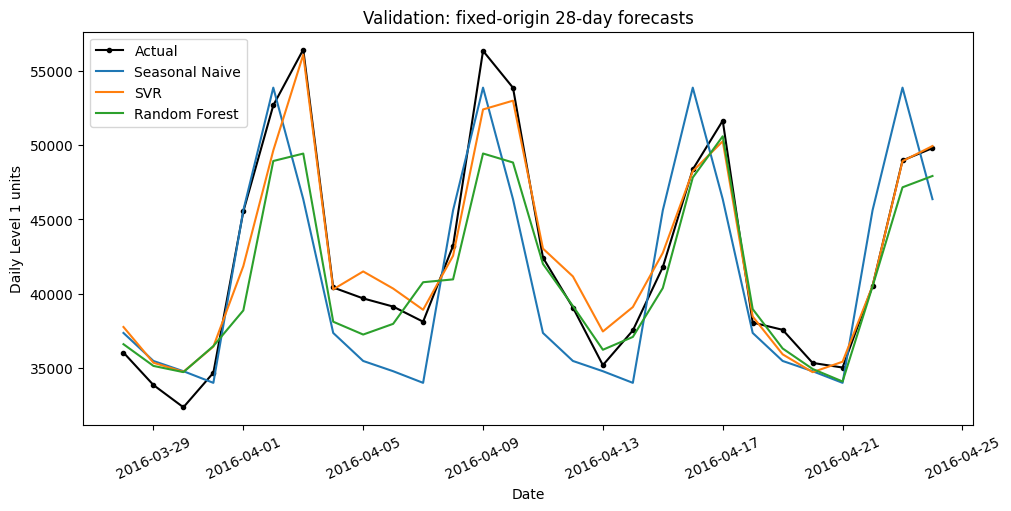

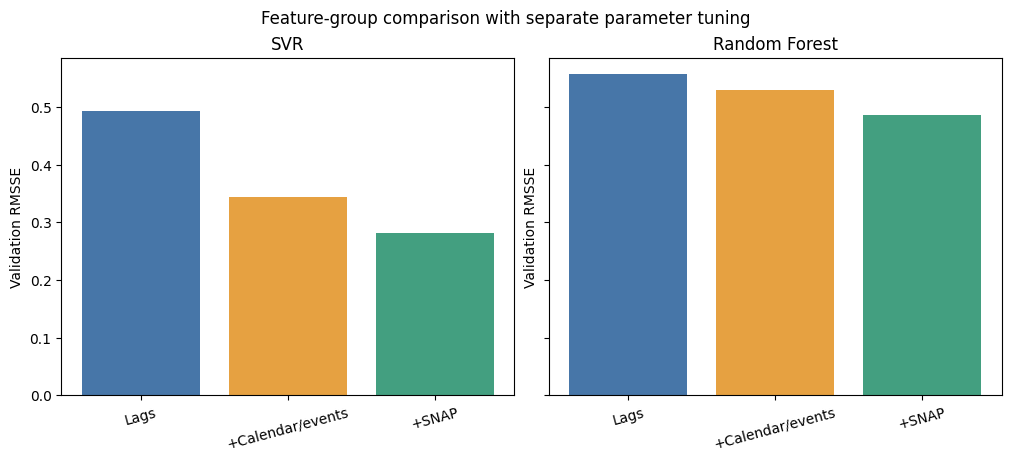

In [12]:
fig_forecast, ax = plt.subplots(figsize=(10, 5), layout='constrained')
target = development.iloc[1885:1913]
ax.plot(target['date'], target['total_sales'], color='black', marker='o', markersize=3, label='Actual')
plot_ids = ['seasonal_naive_7'] + [c['config_id'] for c in selected_models]
for cid in plot_ids:
    p = cv_predictions[cv_predictions['config_id'].eq(cid) & cv_predictions['fold'].eq(3)]
    name = comparison_summary[comparison_summary['config_id'].eq(cid)].iloc[0]['model']
    ax.plot(pd.to_datetime(p['date']), p['prediction'], label=name)
ax.set(title='Validation: fixed-origin 28-day forecasts', ylabel='Daily Level 1 units', xlabel='Date')
ax.legend()
ax.tick_params(axis='x', rotation=25)
plt.show()

fig_ablation, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True, layout='constrained')
for ax, family in zip(axes, ['SVR', 'Random Forest']):
    rows = ablation_summary[ablation_summary['model'].eq(family)].set_index('feature_group').loc[list(FEATURE_GROUPS)]
    ax.bar(range(3), rows['validation_rmsse'], color=['#4776a8', '#e6a141', '#439f80'])
    ax.set_xticks(range(3), ['Lags', '+Calendar/events', '+SNAP'], rotation=15)
    ax.set_title(family)
    ax.set_ylabel('Validation RMSSE')
fig_ablation.suptitle('Feature-group comparison with separate parameter tuning')
plt.show()

## 6. Save selected models, parameters and reproducibility evidence

Six Validation-fitted group winners are saved, including the two family-level
selections. Each model carries its ordered feature names and schema. Scalers
are included in the SVR object. Versions and file hashes are logged because
serialized sklearn objects are tied to their training environment.

Saved model files and prediction CSVs belong on Drive. Small result tables,
figures and JSON metadata may also be archived in GitHub after run verification.
This notebook does not open Test or refit on Train+Validation for Test.

In [13]:
artifact_dir = output_dir / '04_Outputs_and_Artifacts'
table_dir, figure_dir = artifact_dir / 'table', artifact_dir / 'figures'
model_dir = artifact_dir / 'models_saved' / 'svr_rf'
prediction_dir = output_dir / '02_Data' / 'predictions'
for directory in [table_dir, figure_dir, model_dir, prediction_dir]:
    directory.mkdir(parents=True, exist_ok=True)
versions = {name: metadata.version(name) for name in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib', 'matplotlib', 'threadpoolctl']}
exported_paths = []
model_records = []
for config in selected_group_configs:
    key = (config['family'], config['feature_group'])
    _, F, names, _ = select_columns(bundles[3], config['feature_group'])
    estimator = winner_models[key]
    path = model_dir / (config['config_id'] + '.joblib')
    payload = {'estimator': estimator, 'config': config, 'feature_names': names,
               'feature_schema': bundles[3]['schema'], 'training_origin_day': 1885,
               'training_rows': 1802, 'seed': SEED, 'versions': versions}
    joblib.dump(payload, path, compress=3)
    restored = joblib.load(path)
    require(np.allclose(np.maximum(restored['estimator'].predict(F), 0), winner_forecasts[key],
                        rtol=1e-12, atol=1e-8), 'Serialized model predictions changed.')
    model_records.append({'config': config, 'path': path.relative_to(output_dir).as_posix(),
                          'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
                          'selected_for_family': config['config_id'] in [c['config_id'] for c in selected_models],
                          'feature_names': names})
    exported_paths.append(path)
tables = {'svr_rf_candidate_search.csv': search_results, 'svr_rf_fit_log.csv': fit_log,
          'svr_rf_cv_scores.csv': cv_scores, 'svr_rf_ablation_summary.csv': ablation_summary,
          'svr_rf_comparison_summary.csv': comparison_summary,
          'svr_rf_feature_inventory.csv': feature_dictionary,
          'svr_rf_feature_checks.csv': leakage_checks}
for name, frame in tables.items():
    path = table_dir / name
    frame.to_csv(path, index=False)
    exported_paths.append(path)
for name, frame in [('svr_rf_search_predictions.csv', search_predictions),
                    ('svr_rf_cv_predictions.csv', cv_predictions)]:
    path = prediction_dir / name
    frame.to_csv(path, index=False)
    exported_paths.append(path)
for name, figure in [('svr_rf_validation_forecasts.png', fig_forecast),
                      ('svr_rf_feature_groups.png', fig_ablation)]:
    path = figure_dir / name
    figure.savefig(path, dpi=300)
    exported_paths.append(path)
manifest = {
    'schema_version': 1, 'seed': SEED, 'horizon': HORIZON, 'origins': list(ORIGINS),
    'feature_algorithm_sha256': FEATURE_ALGORITHM_SHA256,
    'feature_schemas': {str(f): bundles[f]['schema'] for f in bundles},
    'selected_models': selected_models, 'group_winners': selected_group_configs,
    'models': model_records,
    'search_space': {'SVR': {'C': [1, 10, 100], 'epsilon': [0.05, 0.10],
                            'gamma': ['scale', 0.01, 0.10], 'kernel': 'rbf',
                            'max_iter': SVR_MAX_ITER, 'tol': 0.001},
                     'Random Forest': {'n_estimators': RF_TREES, 'max_depth': [6, 12, None],
                         'min_samples_leaf': [1, 4], 'max_features': [0.7, 1.0],
                         'criterion': 'squared_error', 'bootstrap': True, 'n_jobs': MODEL_JOBS}},
    'selection': 'Validation RMSSE; group ties: feature_count, config_id; three eligible folds required',
    'group_comparison': 'parameters retuned per feature group',
    'stability_scope': 'three retrospective development windows; includes the selection window',
    'rmsse_denominator': 'all observed sales at the current origin, including warm-up',
    'test_labels_read': False, 'test_forecasts_computed': False, 'versions': versions,
}
manifest_path = artifact_dir / 'svr_rf_selected_configurations.json'
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
exported_paths.append(manifest_path)
report = {
    'status': 'PASS', 'created_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'versions': versions,
    'files_read': ['train.csv', 'val.csv'], 'test_labels_read': False,
    'test_forecasts_computed': False,
    'data_fingerprints': {row['file']: row['table_sha256'] for row in input_inventory},
    'search_candidates': len(search_results), 'eligible_search_candidates': int(search_results['eligible'].sum()),
    'model_fits': len(fit_log), 'excluded_fits': int((~fit_log['eligible']).sum()),
    'cv_score_rows': len(cv_scores), 'cv_forecast_rows': len(cv_predictions),
    'search_forecast_rows': len(search_predictions), 'saved_models': len(model_records),
    'feature_checks_passed': int(leakage_checks['passed'].sum()),
    'selected_cv_clipped_forecasts': int(cv_scores['clipped_forecasts'].sum()),
    'main_comparison': comparison_summary.to_dict(orient='records'),
    'ablation': ablation_summary.to_dict(orient='records'),
    'elapsed_seconds_before_packaging': perf_counter() - RUN_STARTED,
    'files': [path.relative_to(output_dir).as_posix() for path in exported_paths],
}
report_path = artifact_dir / 'svr_rf_run_report.json'
report_path.write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
exported_paths.append(report_path)
zip_path = output_dir / '06_svr_random_forest_results.zip'
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as archive:
    for path in exported_paths:
        archive.write(path, path.relative_to(output_dir).as_posix())
with ZipFile(zip_path) as archive:
    require(archive.testzip() is None and len(archive.namelist()) == 19, 'Incomplete results archive.')
print('SVR/RANDOM FOREST CHECK PASSED')
print(f'Validation candidates: {len(search_results)}; model fits: {len(fit_log)}; excluded fits: {int((~fit_log["eligible"]).sum())}')
print(f'Folds: 3; comparison models: {len(comparison_summary)}; saved models: {len(model_records)}')
print(f'CV forecast rows: {len(cv_predictions)}; feature checks: 24/24')
print(f'Download: {zip_path}')

SVR/RANDOM FOREST CHECK PASSED
Validation candidates: 90; model fits: 102; excluded fits: 0
Folds: 3; comparison models: 6; saved models: 6
CV forecast rows: 840; feature checks: 24/24
Download: /kaggle/working/06_svr_random_forest_results.zip


## Interpretation limits and references

Compare the two selected families with the four baseline configurations using
the common observed-history RMSSE scales. Previous ARIMA-family results remain
separate audited artifacts for the final consolidated comparison. A lower
Validation error is not proof of superiority on Test or every season.

The RBF SVR capacity is controlled by C, epsilon and gamma; feature/target
standardization is part of its training procedure. Forests average bootstrap
trees and use sampled feature subsets at splits. The declared grid and actual
warnings, exclusion records, fit runtimes and chosen parameters must be reported.

Official documentation:
[SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html),
[RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html),
[TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html),
[training-only preprocessing](https://scikit-learn.org/stable/common_pitfalls.html).